# J0 · Install Julia and Pizzetti.jl

**Level:** beginner · **Prerequisites:** none · **Run time:** ~5 min (downloads and
precompilation, once)

**Covers:** installing Julia with `juliaup`, adding Pizzetti.jl, running these notebooks in
Jupyter or VS Code, setting up the environment of the examples, and checking that everything
works. If Julia is already installed, skip to [step 2](#2.-Add-Pizzetti.jl).

## 1. Install Julia

The recommended installer is [`juliaup`](https://github.com/JuliaLang/juliaup), the official
version manager. It installs the current release and keeps it up to date.

On Linux and macOS, in a terminal:

```
curl -fsSL https://install.julialang.org | sh
```

On Windows, in a command prompt (or install *Julia* from the Microsoft Store):

```
winget install --name Julia --id 9NJNWW8PVKMN -e -s msstore
```

Open a new terminal and start Julia with `julia`. Useful `juliaup` commands:

```
juliaup status          # installed versions; the default is marked with *
juliaup update          # update to the latest release
juliaup add 1.10        # install another version (e.g. the long-term-support release)
```

Pizzetti.jl needs Julia ≥ 1.10; the examples environment needs Julia ≥ 1.11 (it locates the
package through a `[sources]` section). Other installation options are listed at
[julialang.org/downloads](https://julialang.org/downloads/).

## 2. Add Pizzetti.jl

The package lives in the `julia/` folder of the
[pizzetti repository](https://github.com/hippke/pizzetti). In the Julia REPL, press `]` to
enter the package manager and type

```
pkg> add https://github.com/hippke/pizzetti:julia
```

or, equivalently, from Julia code:

```julia
using Pkg
Pkg.add(url = "https://github.com/hippke/pizzetti", subdir = "julia")
```

Pizzetti.jl depends only on SpecialFunctions. Two optional packages switch on extensions as
soon as they are loaded next to it: [ForwardDiff](https://github.com/JuliaDiff/ForwardDiff.jl)
(exact derivatives, J1, J2, J4) and
[IntervalArithmetic](https://github.com/JuliaIntervals/IntervalArithmetic.jl)
(rigorous enclosures, J3).

## 3. Jupyter or VS Code

These tutorials are Jupyter notebooks with a Julia kernel. Two ways to run them:

- **Jupyter.** Add [IJulia](https://github.com/JuliaLang/IJulia.jl), which registers a Julia
  kernel with Jupyter:

  ```
  pkg> add IJulia
  julia> using IJulia; notebook(dir = ".")     # or `jupyter lab` if Jupyter is already installed
  ```

  If no Jupyter installation is found, `notebook()` offers to install one through Conda.
  Choose the kernel *Julia 1.x* when a notebook asks for it.
- **VS Code.** The [Julia extension](https://www.julia-vscode.org/) opens `.ipynb` files
  directly; pick the Julia kernel in the top-right corner.

Every notebook is also a plain script (`J1_quickstart.jl`, …) in the same folder, which runs
from a terminal with `julia --project=. J1_quickstart.jl`.

## 4. The environment of the examples

The examples use a few more packages (Plots, Optim, NbodyGradient, Limbdark, BenchmarkTools,
…), recorded in `julia/examples/Project.toml`. Clone the repository and instantiate this
environment once:

```
git clone https://github.com/hippke/pizzetti
cd pizzetti/julia/examples
julia --project=. -e 'using Pkg; Pkg.instantiate()'
```

This installs the package set of the examples, including Pizzetti.jl from the folder above
(so local changes to the package are picked up). Start Jupyter from this folder: the IJulia
kernel activates the environment of the folder it starts in (`--project=@.`), so the
notebooks find all their packages.

## 5. Check the installation

The cells below are what a working installation prints. In a notebook opened from
`julia/examples`, the first line activates the examples environment (in a script run with
`--project=.` it is already active).

In [1]:
using Pkg, InteractiveUtils
Pkg.activate(@__DIR__; io = devnull)
Pkg.status(["Pizzetti", "ForwardDiff", "IntervalArithmetic", "Plots"])

Status `pizzetti/julia/examples/Project.toml`
  [f6369f11] ForwardDiff v1.4.6
  [d1acc4aa] IntervalArithmetic v1.0.12
  [b93e7ce5] Pizzetti v0.2.0 `..`
  [91a5bcdd] Plots v1.41.7


The Julia version and the machine on which this notebook was built:

In [2]:
versioninfo()

Julia Version 1.13.1
Commit 96ca370cf0e (2026-09-25 19:34 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 20 × 13th Gen Intel(R) Core(TM) i5-13500
  WORD_SIZE: 64
  LLVM: libLLVM-20.1.8 (ORCJIT, raptorlake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 20 virtual cores)


Load the package and compute the flux of a star with power-2 limb darkening,
$I(\mu) = 1 - c\,(1 - \mu^\alpha)$, occulted by a planet of radius ratio $p = 0.1$ at four
projected separations $z$ (in stellar radii):

In [3]:
using Pizzetti
occult([0.0, 0.5, 0.95, 1.05], 0.1, Power2(0.6, 0.6))

4-element Vector{Float64}:
 0.9884033280505852
 0.9889845552077373
 0.9934649431396444
 0.9986520901005472

The first call compiles the code (a few seconds); later calls take nanoseconds per sample.
A transit light curve of a hot Jupiter, from orbital elements:

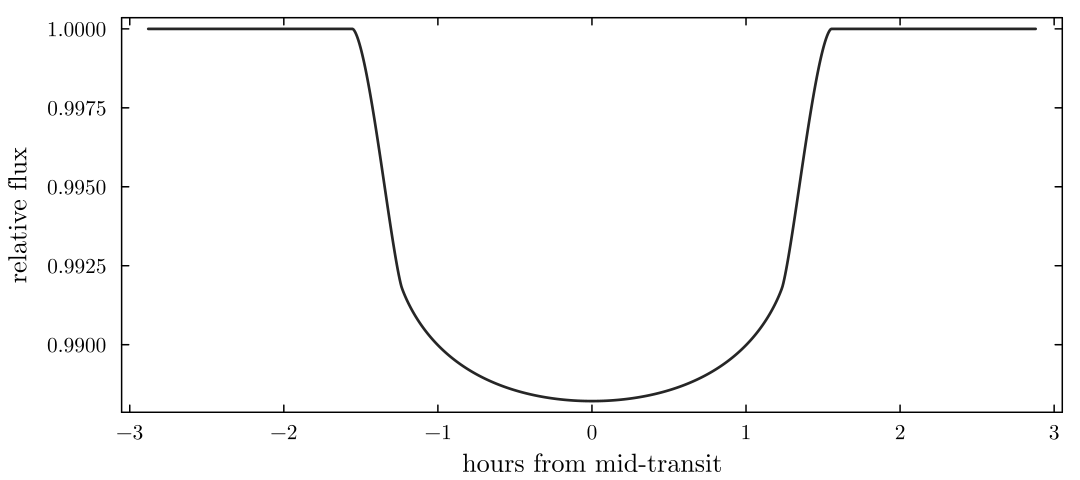

In [4]:
include("theme.jl")                     # the plotting style of these notebooks (Plots.jl)
prm = TransitParams(per = 3.5, rp = 0.1, a = 9.0, b = 0.35, law = Quadratic(0.40, 0.25))
t = range(-0.12, 0.12, length = 1000)   # days from mid-transit
plot(24t, light_curve(t, prm), color = COLORS.ink, legend = false, size = (720, 320),
     xlabel = "hours from mid-transit", ylabel = "relative flux")

Loading ForwardDiff switches on exact derivatives. The gradient of the flux with respect to
$(z, p, c, \alpha)$ at $z = 0.95$, near the limb:

In [5]:
using ForwardDiff
ForwardDiff.gradient(v -> occult(v[1], v[2], Power2(v[3], v[4])), [0.95, 0.1, 0.6, 0.6])

4-element Vector{Float64}:
  0.05330839933551284
 -0.11145997876543198
  0.0027824347482397925
  0.0016878386693334297

## 6. Run the test suite (optional)

The package comes with about 6000 tests against independent references (a few minutes):

```
pkg> test Pizzetti
```

## Next

Everything works? Continue with [J1 · Pizzetti.jl in ten minutes](J1_quickstart.ipynb).

If something does not, please open an [issue](https://github.com/hippke/pizzetti/issues)
with the output of `versioninfo()` and `Pkg.status()`.